# 05-01 - Chips and Masks

You see the data behind the lecture's footprint model, Princeton cut into chips with a mask drawn from the volunteers' footprints, and you train a first head on it.

We start with the whole window and the blocks dealt out before any training. Then we read one test block at full size, cut the window into chips, look at the first batch, fit a head on the frozen features and draw the feature space. At the end you change the size of the blocks.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seg_tools as seg

plt.rcParams["figure.dpi"] = 72

scene = seg.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p05"]
torch_ok = seg.torch_available()
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready


## The window and the mask

The cell reads the window at 2.4 m, draws it with the 25 blocks tinted by their role, and draws the roof share of every cell beside it.

10,240 pixels a side at 0.3 m, 3072 m across, from 2023-08-20
roof on 10.8% of the window   reference 10.8%


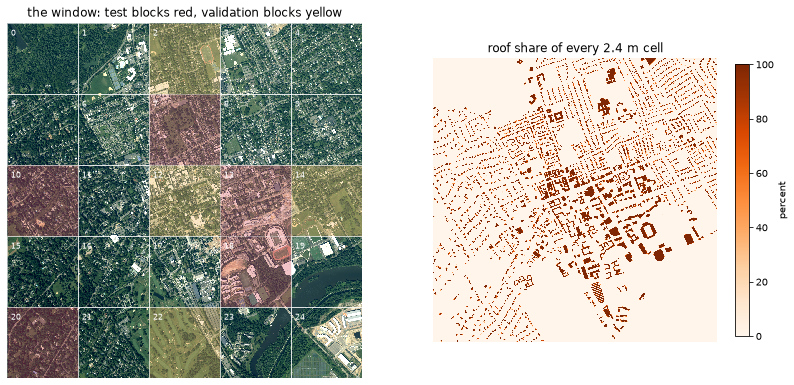

In [2]:
small, transform = seg.read_rgb("data/window_2m4.tif")
share, *_ = seg.read_raster("data/mask_2m4.tif")
blocks = gpd.read_file("data/layers.gpkg", layer="blocks")
w = scene["window"]
print(f"{w['pixels']:,} pixels a side at {w['resolution_m']} m, {w['metres']:.0f} m across, from {w['date']}")
print(f"roof on {share.mean() / 100:.1%} of the window   reference {reference['window']['mask_share']:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
seg.show_window(axes[0], small, blocks, "the window: test blocks red, validation blocks yellow")
seg.show_image(axes[1], share, "roof share of every 2.4 m cell", cmap="Oranges", vmin=0, vmax=100,
               label="percent")

The left picture is three kilometres of Princeton around Nassau Hall, photographed from an aircraft in August 2023 at 30 cm and averaged to 2.4 m here. The grid is 25 blocks of 614 m. Five red blocks are the test, never trained on; four yellow blocks tell the training when to stop; sixteen train. The right picture is the label, the share of each cell inside a footprint the OpenStreetMap volunteers drew. That percentage is how much of the town is roof.

## The mask rule at full size

The cell reads the residential test block at 30 cm with its mask and its footprints, and draws the mask over the picture.

block 7: 2048 by 2048 pixels at 0.3 m, 338 footprints   reference 338
roof on 16.0% of the block   reference 16.0%


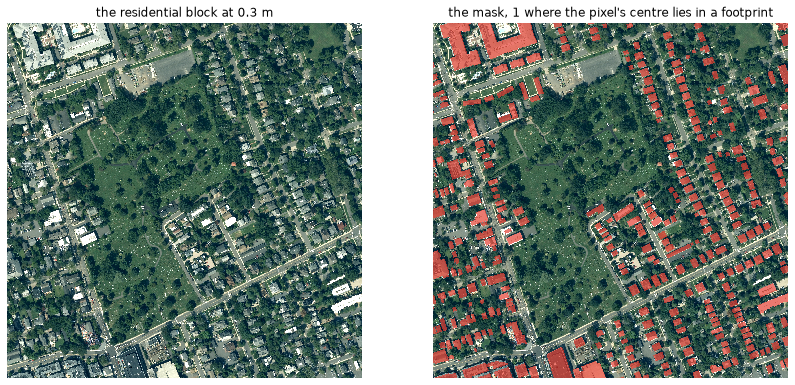

In [3]:
image, transform, crs, res = seg.read_raster("data/block_7.tif")
mask, *_ = seg.read_raster("data/mask_7.tif")
footprints = gpd.read_file("data/layers.gpkg", layer="footprints_7")
picture = seg.stretch(image)
print(f"block {scene['block']['id']}: {image.shape[1]} by {image.shape[2]} pixels at {res} m, "
      f"{len(footprints)} footprints   reference {reference['block']['footprints']}")
print(f"roof on {mask.mean():.1%} of the block   reference {reference['block']['share']:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
seg.show_image(axes[0], picture, "the residential block at 0.3 m")
seg.show_mask(axes[1], picture, mask > 0, "the mask, 1 where the pixel's centre lies in a footprint")

Block 7 is the residential square of the Lecture 04 quiz, and a test block. A pixel of the mask is 1 when its centre lies inside a footprint, the centre-in rule of Lecture 04. Look at the roofs under the trees. The volunteers drew them whole, the picture shows what the canopy leaves open, and the network is asked to find all of it. Driveways and sheds are roof-coloured and not roof. The mask is the question, and it is the volunteers' answer, three years newer than the picture.

## Chips and the split

The cell reads the table of the 1,600 chips, counts them by role, and draws the 64 chips of the block.

1,600 chips of 256 pixels, 76.8 m a side
training 1,024, validation 256, test 320   reference 1,024, 256, 320
1,079 chips hold a building at the 2.5% rule   reference 1,079


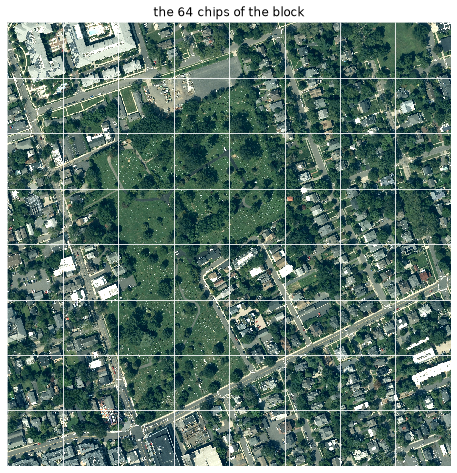

In [4]:
chips = seg.chip_table("data/chips.csv")
counts, tiled = chips["split"].value_counts(), reference["chips"]["tiled"]
print(f"{len(chips):,} chips of {scene['chips']['size_px']} pixels, {scene['chips']['metres']:.1f} m a side")
print(f"training {counts['train']:,}, validation {counts['val']}, test {counts['test']}"
      f"   reference {tiled['train']:,}, {tiled['val']}, {tiled['test']}")
print(f"{int(chips['label'].sum()):,} chips hold a building at the {scene['chips']['label_share']:.1%} rule"
      f"   reference {tiled['with_building']:,}")
here = seg.block_chips(chips, scene["block"]["id"])
origin = (here["row"].min(), here["col"].min())
fig, ax = plt.subplots(figsize=(8, 8))
seg.show_grid(ax, picture, here["row"], here["col"], origin=origin,
              title=f"the {len(here)} chips of the block")

A chip is 256 pixels square, 77 m of ground, the unit the network reads. Cut edge to edge the window gives 1,600 chips, each inside its block, so a split of the blocks is a split of the chips. The second line counts them by role. A chip holds a building when at least 2.5 percent of its pixels are roof, about one house. The lecture also cut chips that overlap by half, 5,625 of them, to train on. This table is the tiled one.

## The first batch

The cell reads the 32 chips of the first batch of the lecture's chip classifier and draws them framed by their label.

32 chips, 22 with a building   reference 22
32 of them come out again from the seed


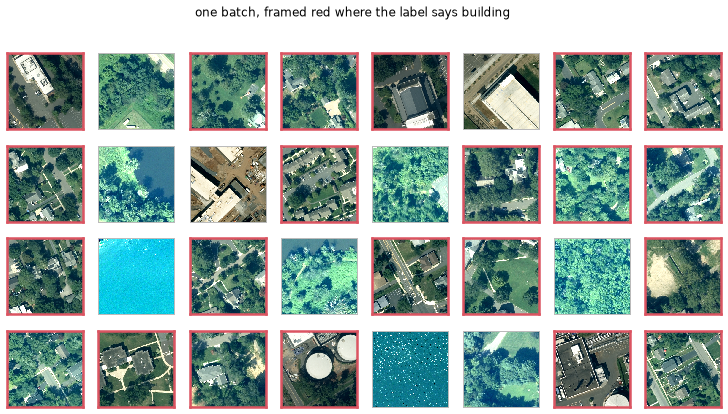

In [5]:
batch = seg.read_npz("data/first_batch.npz")
replayed = seg.first_batch(chips, seed=scene["seed"])
same = int((replayed == batch["index"]).sum())
print(f"{len(batch['index'])} chips, {int(batch['label'].sum())} with a building"
      f"   reference {reference['chips']['first_batch']['with_building']}")
print(f"{same} of them come out again from the seed")
fig = seg.show_batch(batch["images"], batch["label"])

Training moves the weights one batch at a time, and this is the first batch the lecture's classifier saw: 32 chips, shuffled from the training blocks by a random generator given a seed. The frames carry the labels, red for a building. The second line replays the shuffle from the same seed and gets the same chips, what a seed is for. Every chip entered turned or mirrored at random, one of the eight symmetries of a square, and 32 batches made an epoch.

## A head on the frozen features

The cell fits a logistic head on the 512 frozen numbers of the training chips and scores it on the test chips, under two splits.

In [6]:
F = seg.read_npz("data/chip_features.npz")
labels, split, ref_h = F["labels"].astype(int), F["split"], reference["head"]
train, test = split == 0, split == 2
head = seg.fit_head(F["frozen"], labels, train)
block_acc = seg.head_accuracy(head, F["frozen"], labels, np.flatnonzero(test))
rtrain, rtest = seg.random_split(len(labels), int(train.sum()), int(test.sum()), scene["seed"])
head_r = seg.fit_head(F["frozen"], labels, rtrain)
random_acc = seg.head_accuracy(head_r, F["frozen"], labels, np.flatnonzero(rtest))
baseline, tuned = max(labels[test].mean(), 1 - labels[test].mean()), reference["lecture"]["classifier"]
print(f"a head on the frozen numbers, test blocks {block_acc:.1%}   reference {ref_h['block_split']:.1%}")
print(f"the same head under a random split {random_acc:.1%}   reference {ref_h['random_split']:.1%}")
print(f"a building everywhere {baseline:.1%}; the lecture's network {tuned['finetuned']['test_acc']:.1%}")

a head on the frozen numbers, test blocks 90.0%   reference 90.0%
the same head under a random split 90.0%   reference 90.0%
a building everywhere 76.6%; the lecture's network 91.9%


The frozen numbers are what Lecture 04's ImageNet network says about a chip it has never seen. A head is one more layer of 513 weights, here a logistic regression penalised against memorising a thousand chips in 512 dimensions. The first line is its score on the five test blocks, the second the same recipe with chips dealt at random. Compare both with the baseline and the lecture's fine-tuned network, all eleven million weights moved. The frozen numbers carry more than the lecture's early-stopped head got from them.

## The feature space

The cell draws the 320 test chips as points in the feature space of the frozen body and of the fine-tuned body, and fits a head on the fine-tuned numbers.

a head on the fine-tuned numbers 92.2%   reference 92.2%


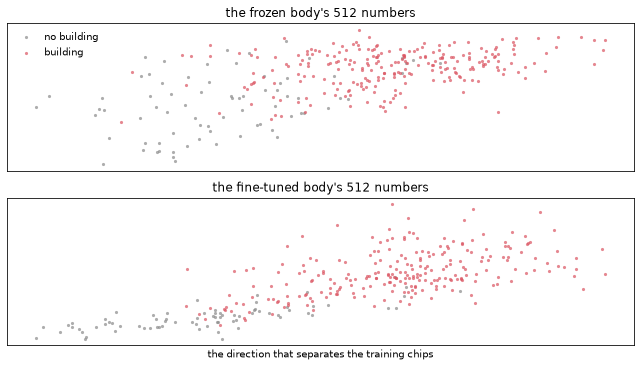

In [7]:
head_t = seg.fit_head(F["finetuned"], labels, train)
tuned_acc = seg.head_accuracy(head_t, F["finetuned"], labels, np.flatnonzero(test))
print(f"a head on the fine-tuned numbers {tuned_acc:.1%}   reference {ref_h['finetuned_features']:.1%}")
fig = seg.show_feature_space([F["frozen"], F["finetuned"]], labels, train, np.flatnonzero(test),
                             ["the frozen body's 512 numbers", "the fine-tuned body's 512 numbers"])

Each point is a test chip placed by two directions through the 512 numbers, the one that best separates the training chips with a building from those without, and one orthogonal to it. Red is a building. In the upper panel the two clouds overlap along a band, in the lower they pull apart, because fine-tuning moved the body's weights toward Princeton's roofs. The printed line is a head on the fine-tuned numbers, close to the network's own score, because the last layer is a line through this picture.

## Your turn

The blocks are 614 m, and at that size the cell starts from the lecture's split. Halve them, so that every chip has test neighbours twice as close, and fit the head again under the new deal. Run the cell as it is, then change the marked value and run it again.

Did the number move, and which way? What would a much larger move have told you about the chips and their neighbours? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [8]:
BLOCK_M = 614.4  # change me: 307.2
train2, test2 = seg.split_by_blocks(chips, BLOCK_M, seed=scene["seed"])
head2 = seg.fit_head(F["frozen"], labels, train2)
acc2 = seg.head_accuracy(head2, F["frozen"], labels, np.flatnonzero(test2))
print(f"blocks of {BLOCK_M:.0f} m: {int(test2.sum())} test chips, the head gets {acc2:.1%} right")

blocks of 614 m: 320 test chips, the head gets 90.0% right


## Check your understanding

1. What does the mask say at a pixel under a tree where the volunteers drew a roof, and why does that make the model's job harder than the picture suggests?
2. Why are the blocks dealt out before any training, and what would go wrong if chips were dealt at random instead?
3. A chip holds a building when 2.5 percent of its pixels are roof. What changes if the rule is raised to 10 percent?
4. The head on the frozen numbers scores close to the fine-tuned network. What does fine-tuning still buy, and what did it cost?

## Where we are

You have seen the window, its mask and the blocks dealt out before any training, cut the window into chips and read the first batch, and fitted a head of 513 weights on the frozen numbers under two splits. You now know what the model is asked, how rare the class is, and how much a head on a frozen body already knows. In 05-02 the U-Net answers at every pixel of this block.

## Further resources

Nothing in this course requires anything below.

- GeoAI with Python, chapter 9 on image segmentation, Qiusheng Wu, 2026, https://geoai.gishub.org
- Understanding Deep Learning, chapter 9 on regularisation and chapter 10 on convolutional networks, Simon Prince, MIT Press, 2023, https://udlbook.github.io/udlbook/
- Hands-On Machine Learning with Scikit-Learn and PyTorch, chapter 11 on transfer learning, Aurélien Géron, O'Reilly, 2025

The model, its weights, its outputs and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. The footprints are an OpenStreetMap extract, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright